# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [4]:
# YOUR CODE HERE
import glob
from datasets import load_dataset

# 1. Find corporate policy files
policy_files = glob.glob("corporate_policies/**/*.md", recursive=True)

print("Corporate policy files found:")
for file in policy_files:
    print(file)

print(f"\nTotal policy files: {len(policy_files)}")


# 2. Load the Bitext customer support dataset
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

# 3. Print dataset information
print("\nDataset information:")
print(dataset)

# 4. Inspect the training split
train_data = dataset["train"]

print("\nNumber of rows:", len(train_data))
print("Columns:", train_data.column_names)

# 5. Display sample records
print("\nFirst 5 records:")
for row in train_data.select(range(5)):
    print(row)

Corporate policy files found:
corporate_policies/shipping_delays.md
corporate_policies/escalation_matrix.md
corporate_policies/refund_policy.md
corporate_policies/password_reset.md
corporate_policies/technical_troubleshooting.md

Total policy files: 5

Dataset information:
DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})

Number of rows: 26872
Columns: ['flags', 'instruction', 'category', 'intent', 'response']

First 5 records:
{'flags': 'B', 'instruction': 'question about cancelling order {{Order Number}}', 'category': 'ORDER', 'intent': 'cancel_order', 'response': "I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the information you need. Please go ahead and ask your question, and I'll do my best to assist you."}
{'flags': 'BQZ', 'instruction': 'i have a question about cancelling oorder {{Order Number}}', 'category': 'ORDER'

#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [5]:
# YOUR CODE HERE
import pandas as pd
from datasets import load_dataset

# 1. Load the Bitext customer support dataset
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

# 2. Convert the training split into a pandas DataFrame
df = dataset["train"].to_pandas()

# 3. Calculate the original dataset size
original_size = len(df)
print("Original dataset size:", original_size)

# 4. Calculate the number of unique intents
unique_intents = df["intent"].nunique()
print("Number of unique intents:", unique_intents)

# 5. Randomly sample 4,000 rows
df_sampled = df.sample(n=4000, random_state=42)

# 6. Print sampled dataset information
print("\nSampled dataset size:", len(df_sampled))
print("Unique intents in sampled dataset:", df_sampled["intent"].nunique())

# 7. Display the first 5 sampled records
print("\nFirst 5 sampled records:")
print(df_sampled.head())

# 8. Display the number of samples per intent
print("\nSamples per intent:")
print(df_sampled["intent"].value_counts().sort_index())

Original dataset size: 26872
Number of unique intents: 27

Sampled dataset size: 4000
Unique intents in sampled dataset: 27

First 5 sampled records:
       flags                                        instruction category  \
9329     BLZ                   I can't talk with  a human agent  CONTACT   
4160    BLMZ  I have got to locate hte bills from {{Person N...  INVOICE   
18500  BCELM  I cannot pay, help me to inform of a problem w...  PAYMENT   
8840      BL           I want help speaking to customer service  CONTACT   
5098     BLZ           I try to see th accepted payment options  PAYMENT   

                         intent  \
9329        contact_human_agent   
4160              check_invoice   
18500             payment_issue   
8840   contact_customer_service   
5098      check_payment_methods   

                                                response  
9329   Thank you for reaching out! I'm sorry to hear ...  
4160   I'll get right on it! I understand your need t...  
18500

#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [6]:
# YOUR CODE HERE
# 1. Check for null values
print("Null values before cleaning:")
print(df_sampled.isnull().sum())

# 2. Remove records containing null values
df_clean = df_sampled.dropna().copy()

print("\nRows after removing null values:", len(df_clean))

# 3. Create a normalized version of the customer instruction
#    Lowercase + remove leading/trailing whitespace
df_clean["instruction_normalized"] = (
    df_clean["instruction"]
    .str.lower()
    .str.strip()
)

# 4. Check for normalized duplicates
duplicate_count = df_clean["instruction_normalized"].duplicated().sum()

print("\nNormalized duplicate instructions:", duplicate_count)

# 5. Remove normalized duplicate instructions
df_clean = df_clean.drop_duplicates(
    subset=["instruction_normalized"],
    keep="first"
).copy()

# 6. Remove the temporary normalization column
df_clean.drop(columns=["instruction_normalized"], inplace=True)

# 7. Final dataset information
print("\nFinal dataset size:", len(df_clean))
print("Rows removed:", len(df_sampled) - len(df_clean))

# 8. Verify that no nulls or duplicate normalized instructions remain
print("\nNull values after cleaning:")
print(df_clean.isnull().sum())

print("\nFinal duplicate check:")
print(
    df_clean["instruction"]
    .str.lower()
    .str.strip()
    .duplicated()
    .sum()
)

Null values before cleaning:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Rows after removing null values: 4000

Normalized duplicate instructions: 98

Final dataset size: 3902
Rows removed: 98

Null values after cleaning:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Final duplicate check:
0


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

Top 10 intents:
intent
review                      166
get_invoice                 165
create_account              163
set_up_shipping_address     159
contact_customer_service    158
check_payment_methods       157
payment_issue               157
contact_human_agent         155
registration_problems       152
complaint                   152
Name: count, dtype: int64

Most frequent intent percentage: 4.25%
No single intent dominates more than 80% of the dataset.


/tmp/ipykernel_3469/4093733649.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


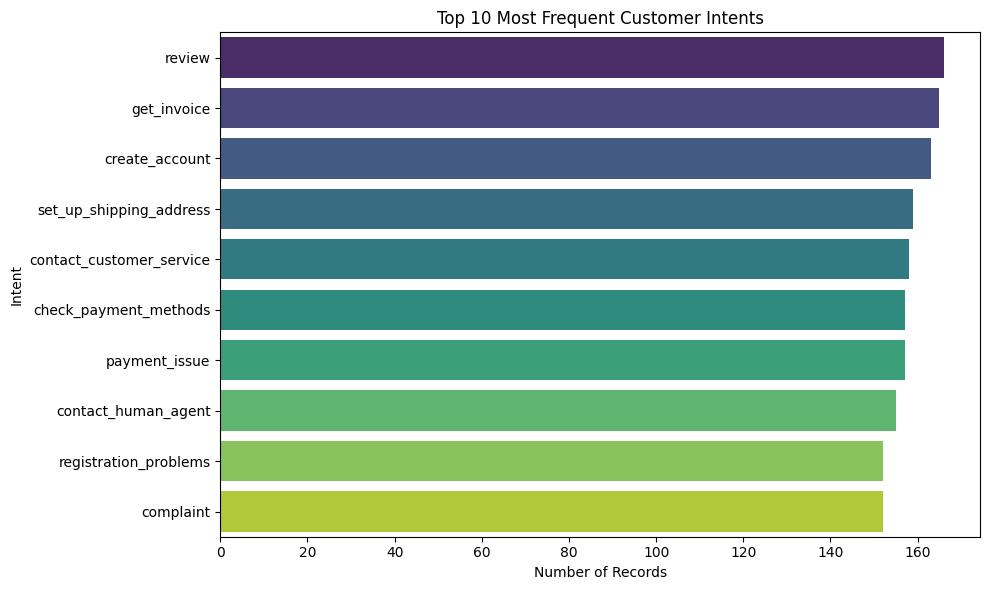

In [3]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 10 most frequent intents
top_10_intents = df_clean["intent"].value_counts().head(10)

print("Top 10 intents:")
print(top_10_intents)

# Check whether the most frequent intent exceeds 80% of the dataset
top_intent_percentage = (
    top_10_intents.iloc[0] / len(df_clean)
) * 100

print(f"\nMost frequent intent percentage: {top_intent_percentage:.2f}%")

if top_intent_percentage > 80:
    print("Severe class imbalance detected.")
else:
    print("No single intent dominates more than 80% of the dataset.")

# Plot top 10 intents
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    y="intent",
    order=top_10_intents.index,
    palette="viridis"
)

plt.title("Top 10 Most Frequent Customer Intents")
plt.xlabel("Number of Records")
plt.ylabel("Intent")
plt.tight_layout()
plt.show()

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [7]:
# YOUR CODE HERE
import glob
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Find all Markdown SOP files
md_files = glob.glob("corporate_policies/**/*.md", recursive=True)

print("Number of Markdown files:", len(md_files))
print("Files:")
for f in md_files:
    print(f)

# Read each file into a list of strings
documents = []

for f in md_files:
    with open(f, "r", encoding="utf-8") as file:
        documents.append(file.read())

print("\nNumber of documents loaded:", len(documents))

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(stop_words="english")

# Fit and transform the SOP documents
tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

feature_names = vectorizer.get_feature_names_out()

print("Number of unique terms:", len(feature_names))
print("\nFirst 20 terms:")
print(feature_names[:20])

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names
)

print(tfidf_df.shape)
print(tfidf_df.head())

Number of Markdown files: 5
Files:
corporate_policies/shipping_delays.md
corporate_policies/escalation_matrix.md
corporate_policies/refund_policy.md
corporate_policies/password_reset.md
corporate_policies/technical_troubleshooting.md

Number of documents loaded: 5
TF-IDF matrix shape: (5, 445)
Number of unique terms: 445

First 20 terms:
['10' '12' '21' '24' '30' '48' '60' 'access' 'accidental' 'account'
 'acknowledge' 'act' 'action' 'actions' 'active' 'actually' 'add'
 'address' 'advise' 'advising']
(5, 445)
         10       12       21        24       30       48        60    access  \
0  0.063801  0.00000  0.07908  0.158161  0.00000  0.07908  0.000000  0.000000   
1  0.000000  0.00000  0.00000  0.000000  0.00000  0.00000  0.000000  0.000000   
2  0.000000  0.06437  0.00000  0.000000  0.06437  0.00000  0.000000  0.000000   
3  0.048347  0.00000  0.00000  0.000000  0.00000  0.00000  0.059924  0.048347   
4  0.000000  0.00000  0.00000  0.000000  0.00000  0.00000  0.000000  0.059365   

#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

Cosine similarity matrix shape: (5, 5)

Cosine similarity matrix:
[[1.         0.08970362 0.25305224 0.0586171  0.06198278]
 [0.08970362 1.         0.10349905 0.05570637 0.18483773]
 [0.25305224 0.10349905 1.         0.04150889 0.05104732]
 [0.0586171  0.05570637 0.04150889 1.         0.11076267]
 [0.06198278 0.18483773 0.05104732 0.11076267 1.        ]]


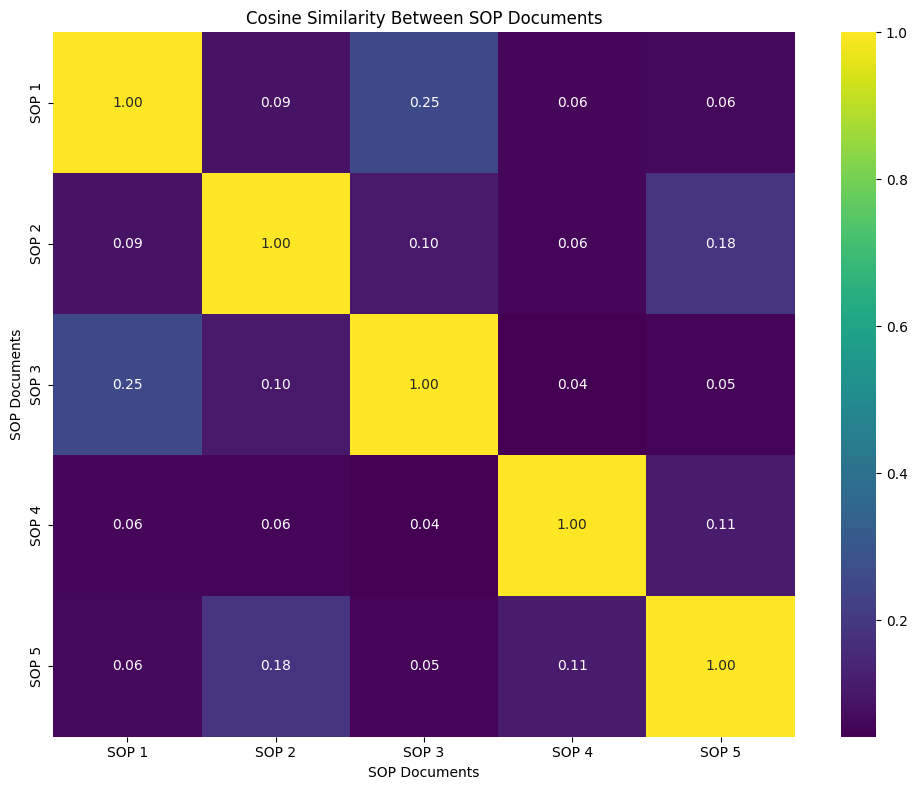

In [8]:
# YOUR CODE HERE
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculate cosine similarity between all SOP document vectors
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Cosine similarity matrix shape:", similarity_matrix.shape)

# 2. Display the similarity matrix
print("\nCosine similarity matrix:")
print(similarity_matrix)

# 3. Plot annotated heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    similarity_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=[f"SOP {i+1}" for i in range(len(documents))],
    yticklabels=[f"SOP {i+1}" for i in range(len(documents))]
)

plt.title("Cosine Similarity Between SOP Documents")
plt.xlabel("SOP Documents")
plt.ylabel("SOP Documents")
plt.tight_layout()
plt.show()

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [9]:
# YOUR CODE HERE
# Save the cleaned DataFrame for use in Notebook 2

output_file = "cleaned_customer_support_data.csv"

df_clean.to_csv(output_file, index=False)

print(f"Cleaned DataFrame saved successfully to: {output_file}")
print("Shape:", df_clean.shape)

Cleaned DataFrame saved successfully to: cleaned_customer_support_data.csv
Shape: (3902, 5)


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**